# 02 - Data Preparation

## Objective

Prepare reproducible training, validation, and test datasets for
brain tumor segmentation using the BRISC 2025 dataset.

This notebook builds on the findings of `01_data_audit.ipynb`.

### Methodological decisions

- Retain the official BRISC train/test partitions as the starting point.
- Exclude test images whose exact SHA256 hash appears in the official training set.
- Create a validation partition from the official training data.
- Prevent exact-image duplicates from crossing training and validation partitions.
- Apply a consistent binary mask threshold of 128.
- Save split manifests and preprocessing parameters for reuse in subsequent notebooks.

### Reproducibility

All split definitions will be saved as CSV files, together with
preprocessing settings and summary statistics.

## 2.1 - Build MRI-mask pairs

In [3]:
from google.colab import userdata
from pathlib import Path
import os

DATA_ROOT = Path("/content/data")
BRISC_ROOT = DATA_ROOT / "brisc2025"

if not (BRISC_ROOT / "manifest.csv").exists():

    print("BRISC dataset not found. Downloading...")

    os.environ["KAGGLE_API_TOKEN"] = userdata.get(
        "KAGGLE_API_TOKEN"
    )

    DATA_ROOT.mkdir(parents=True, exist_ok=True)

    !kaggle datasets download \
        -d briscdataset/brisc2025 \
        -p /content/data \
        --unzip

else:
    print("BRISC dataset already available.")

assert (BRISC_ROOT / "manifest.csv").exists(), (
    "BRISC manifest not found after download."
)

BRISC dataset not found. Downloading...
Dataset URL: https://www.kaggle.com/datasets/briscdataset/brisc2025
License(s): Attribution 4.0 International (CC BY 4.0)
100% 250M/250M [00:02<00:00, 127MB/s]



In [4]:
from pathlib import Path

import numpy as np
import pandas as pd

# Paths
DATA_ROOT = Path("/content/data")
BRISC_ROOT = DATA_ROOT / "brisc2025"

MANIFEST_PATH = BRISC_ROOT / "manifest.csv"

# Reproducibility
RANDOM_STATE = 42
MASK_THRESHOLD = 128

# Load metadata
manifest = pd.read_csv(MANIFEST_PATH)

print("Manifest shape:", manifest.shape)
print("Columns:", manifest.columns.tolist())

Manifest shape: (15586, 16)
Columns: ['relative_path', 'filename', 'task', 'split', 'index', 'tumor_code', 'tumor_label', 'plane_code', 'plane_label', 'sequence', 'is_mask', 'linked_image', 'width', 'height', 'file_size_bytes', 'sha256']


In [5]:
# Keep segmentation records only
seg = manifest[
    manifest["task"] == "segmentation"
].copy()

seg_images = seg[
    ~seg["is_mask"].astype(bool)
].copy()

seg_masks = seg[
    seg["is_mask"].astype(bool)
].copy()

# Normalize paths
def normalize_path(path):
    return str(path).replace("\\", "/")

seg_images["image_key"] = (
    seg_images["relative_path"].apply(normalize_path)
)

seg_masks["image_key"] = (
    seg_masks["linked_image"].apply(normalize_path)
)

# Image metadata
images = seg_images[
    [
        "image_key",
        "relative_path",
        "split",
        "tumor_label",
        "plane_label",
        "sha256"
    ]
].rename(columns={
    "relative_path": "image_relative_path",
    "sha256": "image_sha256"
})

# Mask metadata
masks = seg_masks[
    ["image_key", "relative_path", "sha256"]
].rename(columns={
    "relative_path": "mask_relative_path",
    "sha256": "mask_sha256"
})

# Associate each MRI with its mask
pairs = images.merge(
    masks,
    on="image_key",
    how="left",
    validate="one_to_one",
    indicator=True
)

assert (pairs["_merge"] == "both").all()
assert len(pairs) == 4793

pairs = pairs.drop(columns="_merge")

# Portable paths for future CSV exports
pairs["image_relative_path"] = (
    pairs["image_relative_path"].apply(normalize_path)
)

pairs["mask_relative_path"] = (
    pairs["mask_relative_path"].apply(normalize_path)
)

print("Total MRI–mask pairs:", len(pairs))

print("\nOfficial splits:")
display(pairs["split"].value_counts())

print("\nPathology distribution:")
display(pd.crosstab(pairs["split"], pairs["tumor_label"]))

Total MRI–mask pairs: 4793

Official splits:


,count
split,
train,3933
test,860



Pathology distribution:


tumor_label,glioma,meningioma,pituitary
split,,,
test,254,306,300
train,1147,1329,1457


## 2.2 - Exact train/test leakage correction

The official BRISC segmentation split is used as the starting point.

The data audit identified seven image SHA256 hashes shared between
the official training and test partitions.

To prevent exact-image leakage, test samples whose image SHA256
already occurs in the official training partition are excluded.


In [6]:
# Step 2.2 — Correct exact-image leakage between train and test

official_train = pairs[
    pairs["split"] == "train"
].copy()

official_test = pairs[
    pairs["split"] == "test"
].copy()

# SHA256 hashes present in the official training partition
train_hashes = set(official_train["image_sha256"])

# Identify test images whose exact content appears in train
leakage_mask = official_test["image_sha256"].isin(train_hashes)

excluded_test = official_test[
    leakage_mask
].copy()

corrected_test = official_test[
    ~leakage_mask
].copy()

# Check the number of affected hashes
shared_hashes = (
    set(official_train["image_sha256"])
    & set(official_test["image_sha256"])
)

print("Official train:", len(official_train))
print("Official test:", len(official_test))

print("\nShared SHA256 hashes:", len(shared_hashes))
print("Excluded test images:", len(excluded_test))
print("Corrected test:", len(corrected_test))

# Verify that no exact-image hash remains shared
remaining_overlap = (
    set(official_train["image_sha256"])
    & set(corrected_test["image_sha256"])
)

assert len(shared_hashes) == 7
assert len(remaining_overlap) == 0

print("\nRemaining train/test SHA256 overlap:",
      len(remaining_overlap))

print("\nExcluded images by pathology:")
display(excluded_test["tumor_label"].value_counts())

print("\nCorrected test distribution:")
display(corrected_test["tumor_label"].value_counts())

Official train: 3933
Official test: 860

Shared SHA256 hashes: 7
Excluded test images: 7
Corrected test: 853

Remaining train/test SHA256 overlap: 0

Excluded images by pathology:


,count
tumor_label,
pituitary,5
meningioma,2



Corrected test distribution:


,count
tumor_label,
meningioma,304
pituitary,295
glioma,254


### Train/test leakage correction — Results

The official training partition contains 3,933 images, while the
official test partition contains 860 images.

Seven distinct image SHA256 hashes were shared between these partitions.
Consequently, seven test images were excluded:
- 5 pituitary images
- 2 meningioma images

The corrected test partition contains **853 images**:
- Glioma: 254
- Meningioma: 304
- Pituitary: 295

## 2.3 - Leakage-aware train/validation split

A validation subset is created exclusively from the official
training partition.

The split uses image SHA256 hashes as grouping identifiers,
ensuring that exact duplicate images cannot be distributed
across training and validation.

A fixed random seed (42) is used for reproducibility, with
approximately 15% of samples allocated to validation.


In [7]:
from sklearn.model_selection import GroupShuffleSplit

# Approximately 15% validation
VAL_SIZE = 0.15

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=VAL_SIZE,
    random_state=RANDOM_STATE
)

train_idx, val_idx = next(
    splitter.split(
        official_train,
        groups=official_train["image_sha256"]
    )
)

train_df = official_train.iloc[train_idx].copy()
val_df = official_train.iloc[val_idx].copy()
test_df = corrected_test.copy()

# Verify that no exact-image hash crosses partitions
train_hashes = set(train_df["image_sha256"])
val_hashes = set(val_df["image_sha256"])
test_hashes = set(test_df["image_sha256"])

assert train_hashes.isdisjoint(val_hashes)
assert train_hashes.isdisjoint(test_hashes)
assert val_hashes.isdisjoint(test_hashes)

# Verify completeness
assert len(train_df) + len(val_df) == len(official_train)
assert len(test_df) == 853

print("Final split sizes:")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print("\nSHA256 overlap checks:")
print("Train / Validation:", len(train_hashes & val_hashes))
print("Train / Test:", len(train_hashes & test_hashes))
print("Validation / Test:", len(val_hashes & test_hashes))

print("\nPathology distribution:")
display(
    pd.DataFrame({
        "Train": train_df["tumor_label"].value_counts(),
        "Validation": val_df["tumor_label"].value_counts(),
        "Test": test_df["tumor_label"].value_counts()
    }).fillna(0).astype(int)
)

print("\nAnatomical plane distribution:")
display(
    pd.DataFrame({
        "Train": train_df["plane_label"].value_counts(),
        "Validation": val_df["plane_label"].value_counts(),
        "Test": test_df["plane_label"].value_counts()
    }).fillna(0).astype(int)
)

Final split sizes:
Train: 3345
Validation: 588
Test: 853

SHA256 overlap checks:
Train / Validation: 0
Train / Test: 0
Validation / Test: 0

Pathology distribution:


,Train,Validation,Test
tumor_label,,,
glioma,987,160,254
meningioma,1118,211,304
pituitary,1240,217,295



Anatomical plane distribution:


,Train,Validation,Test
plane_label,,,
axial,1047,196,342
coronal,1177,189,254
sagittal,1121,203,257


### Final data partitions

A group-aware train/validation split was created from the official
BRISC training partition using image SHA256 hashes as grouping keys.

The resulting partitions contain:

- Training: 3,345 images
- Validation: 588 images
- Corrected test: 853 images

All three partitions are mutually disjoint in terms of exact-image
SHA256 hashes.

All tumor pathologies (glioma, meningioma, pituitary) and anatomical
planes (axial, coronal, sagittal) remain represented in each partition.


## 2.4 - Preprocessing

In [8]:
import tensorflow as tf

IMAGE_SIZE = (256, 256)
BATCH_SIZE = 16

def preprocess_pair(image_path, mask_path):
    # Load MRI
    image = tf.io.read_file(image_path)
    image = tf.io.decode_image(
        image, channels=1, expand_animations=False
    )
    image.set_shape([None, None, 1])

    # Load mask
    mask = tf.io.read_file(mask_path)
    mask = tf.io.decode_png(mask, channels=1)

    # Resize
    image = tf.image.resize(
        image, IMAGE_SIZE, method="bilinear"
    )
    mask = tf.image.resize(
        mask, IMAGE_SIZE, method="nearest"
    )

    # Normalize MRI and binarize mask
    image = tf.cast(image, tf.float32) / 255.0
    mask = tf.cast(mask >= MASK_THRESHOLD, tf.float32)

    return image, mask

MRI shape: (256, 256, 1)
Mask shape: (256, 256, 1)
MRI range: 0.0 0.9431372284889221
Mask values: [0. 1.]


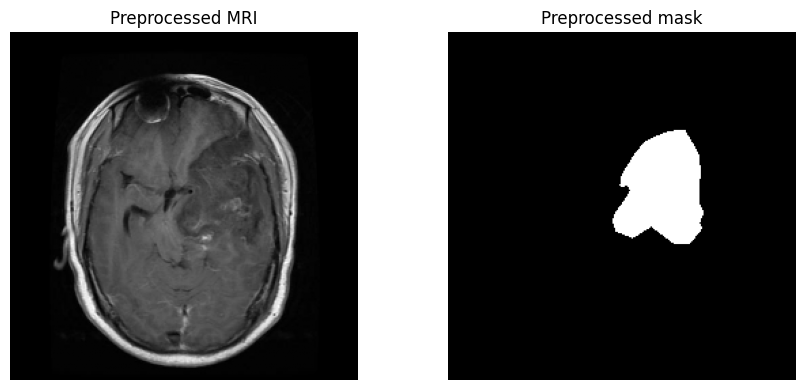

In [9]:
import matplotlib.pyplot as plt

sample = train_df.iloc[0]

image_path = str(
    BRISC_ROOT / sample["image_relative_path"]
)
mask_path = str(
    BRISC_ROOT / sample["mask_relative_path"]
)

image, mask = preprocess_pair(image_path, mask_path)

print("MRI shape:", image.shape)
print("Mask shape:", mask.shape)
print("MRI range:", float(tf.reduce_min(image)),
      float(tf.reduce_max(image)))
print("Mask values:", tf.unique(tf.reshape(mask, [-1]))[0].numpy())

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

axes[0].imshow(image.numpy().squeeze(), cmap="gray")
axes[0].set_title("Preprocessed MRI")

axes[1].imshow(mask.numpy().squeeze(), cmap="gray")
axes[1].set_title("Preprocessed mask")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

### Preprocessing validation

The preprocessing pipeline was successfully tested on a training
image–mask pair.

Both outputs have shape (256, 256, 1). MRI intensities are normalized
to [0, 1], while the segmentation mask contains only binary labels
(0 and 1).

Visual inspection of the preprocessed pair revealed no obvious
spatial misalignment.

The preprocessing configuration is therefore retained for the
baseline U-Net pipeline.

## 2.5 - Build TensorFlow pipelines

In [10]:
# Step 2.5 — Build TensorFlow datasets

AUTOTUNE = tf.data.AUTOTUNE

def build_dataset(df, training=False):

    image_paths = [
        str(BRISC_ROOT / path)
        for path in df["image_relative_path"]
    ]

    mask_paths = [
        str(BRISC_ROOT / path)
        for path in df["mask_relative_path"]
    ]

    # Verify that all referenced files exist
    assert all(Path(p).is_file() for p in image_paths)
    assert all(Path(p).is_file() for p in mask_paths)

    ds = tf.data.Dataset.from_tensor_slices(
        (image_paths, mask_paths)
    )

    if training:
        ds = ds.shuffle(
            buffer_size=len(df),
            seed=RANDOM_STATE,
            reshuffle_each_iteration=True
        )

    ds = ds.map(
        preprocess_pair,
        num_parallel_calls=AUTOTUNE
    )

    ds = ds.batch(BATCH_SIZE)

    ds = ds.prefetch(AUTOTUNE)

    return ds


train_ds = build_dataset(train_df, training=True)
val_ds = build_dataset(val_df)
test_ds = build_dataset(test_df)

print("TensorFlow datasets created.")

TensorFlow datasets created.


In [11]:
# Verify shapes and binary masks

for name, ds in [
    ("Train", train_ds),
    ("Validation", val_ds),
    ("Test", test_ds)
]:
    images_batch, masks_batch = next(iter(ds))

    print(f"\n{name}")
    print("Images:", images_batch.shape)
    print("Masks:", masks_batch.shape)

    print(
        "Image range:",
        float(tf.reduce_min(images_batch)),
        float(tf.reduce_max(images_batch))
    )

    print(
        "Mask values:",
        tf.unique(tf.reshape(masks_batch, [-1]))[0].numpy()
    )


Train
Images: (16, 256, 256, 1)
Masks: (16, 256, 256, 1)
Image range: 0.0 0.9823529124259949
Mask values: [0. 1.]

Validation
Images: (16, 256, 256, 1)
Masks: (16, 256, 256, 1)
Image range: 0.0 0.9784313440322876
Mask values: [0. 1.]

Test
Images: (16, 256, 256, 1)
Masks: (16, 256, 256, 1)
Image range: 0.0 0.9745097756385803
Mask values: [0. 1.]


## 2.6 - Export reusable artifacts

The final dataset partitions and preprocessing configuration are
exported to CSV and JSON files for reproducibility.

These artifacts allow subsequent notebooks to reconstruct the same
training, validation, and test datasets without repeating the data audit
or split-generation procedure.

Only dataset metadata and configuration parameters are exported.
Original MRI images and segmentation masks are not redistributed.

In [12]:
# Step 2.6 — Save reproducible data preparation artifacts

import json
from pathlib import Path

ARTIFACT_DIR = Path("/content/artifacts/data_preparation")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

# Columns to retain in each split
EXPORT_COLUMNS = [
    "image_relative_path",
    "mask_relative_path",
    "tumor_label",
    "plane_label",
    "image_sha256",
    "mask_sha256"
]

# Export final partitions
train_df[EXPORT_COLUMNS].to_csv(
    ARTIFACT_DIR / "train.csv",
    index=False
)

val_df[EXPORT_COLUMNS].to_csv(
    ARTIFACT_DIR / "val.csv",
    index=False
)

test_df[EXPORT_COLUMNS].to_csv(
    ARTIFACT_DIR / "test.csv",
    index=False
)

# Export preprocessing configuration
preprocessing_config = {
    "dataset": "BRISC 2025",
    "image_size": list(IMAGE_SIZE),
    "image_channels": 1,
    "mask_channels": 1,
    "image_normalization": "divide_by_255",
    "mask_threshold": MASK_THRESHOLD,
    "image_interpolation": "bilinear",
    "mask_interpolation": "nearest",
    "batch_size": BATCH_SIZE,
    "random_state": RANDOM_STATE,
    "validation_fraction": VAL_SIZE
}

with open(
    ARTIFACT_DIR / "preprocessing_config.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(preprocessing_config, f, indent=2)

# Export split summary
split_summary = {
    "official_train_count": len(official_train),
    "official_test_count": len(official_test),
    "excluded_test_count": len(excluded_test),
    "shared_official_train_test_hashes": len(shared_hashes),
    "final_train_count": len(train_df),
    "final_val_count": len(val_df),
    "final_test_count": len(test_df),
    "train_val_hash_overlap": len(train_hashes & val_hashes),
    "train_test_hash_overlap": len(train_hashes & test_hashes),
    "val_test_hash_overlap": len(val_hashes & test_hashes),
    "class_distribution": {
        name: df["tumor_label"].value_counts().to_dict()
        for name, df in [
            ("train", train_df),
            ("val", val_df),
            ("test", test_df)
        ]
    },
    "plane_distribution": {
        name: df["plane_label"].value_counts().to_dict()
        for name, df in [
            ("train", train_df),
            ("val", val_df),
            ("test", test_df)
        ]
    }
}

with open(
    ARTIFACT_DIR / "split_summary.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(split_summary, f, indent=2)

print("Saved artifacts:")
for path in sorted(ARTIFACT_DIR.iterdir()):
    print(f" - {path.name} ({path.stat().st_size:,} bytes)")

Saved artifacts:
 - preprocessing_config.json (326 bytes)
 - split_summary.json (899 bytes)
 - test.csv (233,778 bytes)
 - train.csv (930,527 bytes)
 - val.csv (163,682 bytes)


In [13]:
# Reload saved artifacts and verify consistency

saved_train = pd.read_csv(ARTIFACT_DIR / "train.csv")
saved_val = pd.read_csv(ARTIFACT_DIR / "val.csv")
saved_test = pd.read_csv(ARTIFACT_DIR / "test.csv")

with open(
    ARTIFACT_DIR / "preprocessing_config.json",
    encoding="utf-8"
) as f:
    saved_config = json.load(f)

with open(
    ARTIFACT_DIR / "split_summary.json",
    encoding="utf-8"
) as f:
    saved_summary = json.load(f)

assert len(saved_train) == 3345
assert len(saved_val) == 588
assert len(saved_test) == 853

assert saved_config["mask_threshold"] == 128
assert saved_config["image_size"] == [256, 256]

assert set(saved_train["image_sha256"]).isdisjoint(
    set(saved_val["image_sha256"])
)
assert set(saved_train["image_sha256"]).isdisjoint(
    set(saved_test["image_sha256"])
)
assert set(saved_val["image_sha256"]).isdisjoint(
    set(saved_test["image_sha256"])
)

print("All exported artifacts reloaded successfully.")
print("Split sizes:", len(saved_train), len(saved_val), len(saved_test))
print("Image size:", saved_config["image_size"])
print("Mask threshold:", saved_config["mask_threshold"])

All exported artifacts reloaded successfully.
Split sizes: 3345 588 853
Image size: [256, 256]
Mask threshold: 128


## Conclusion

The BRISC segmentation dataset was successfully prepared for
supervised U-Net training.

Three reproducible partitions were established:
- Training: 3,345 images
- Validation: 588 images
- Test: 853 images

The corrected test partition excludes seven images whose exact
SHA256 hashes appeared in the official training partition.
No exact-image hash overlap remains across the three final splits.

MRI images are resized to 256 × 256 and normalized to [0, 1].
Segmentation masks are resized using nearest-neighbor interpolation
and binarized using a threshold of 128.

The TensorFlow data pipeline was successfully initialized and
validated on sample batches from all three partitions.

Five reusable artifacts were exported and successfully reloaded:
`train.csv`, `val.csv`, `test.csv`, `preprocessing_config.json`,
and `split_summary.json`.

These artifacts define the data preparation protocol for subsequent
segmentation experiments.

In [14]:
import shutil

zip_path = shutil.make_archive(
    "/content/data_preparation_artifacts",
    "zip",
    root_dir="/content/artifacts",
    base_dir="data_preparation"
)

from google.colab import files
files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>